# Model Sweep: ElasticNet

Point-in-time cross-sectional stock-selection signal fed into a constrained long-only `ScoreVariance` optimiser with quarterly rebalancing. Runs a 64-point grid over risk aversion, turnover penalty and maximum stock weight, then tests SPI moving-average overlay windows. Results are written to `ml_stock_selection/sweep_results_*` (not tracked in git).


In [ ]:
# Setup and imports
import os, sys, json, pickle, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_repo_root(start=None):
    """Walk up from the notebook folder to the repository root."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'framework').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate the repository root (folder containing framework/).')

REPO_ROOT = find_repo_root()
DATA_PATH = REPO_ROOT / 'data'
for module_dir in ('framework', 'signals', 'data_utils'):
    if str(REPO_ROOT / module_dir) not in sys.path:
        sys.path.insert(0, str(REPO_ROOT / module_dir))
RF_CSV = DATA_PATH / 'IRSTCI01CHM156N.csv'
missing = [f for f in ['market_data.parquet', 'jkp_data.parquet', 'spi_index.csv', 'IRSTCI01CHM156N.csv'] if not (DATA_PATH / f).exists()]
if missing:
    raise FileNotFoundError(f'Missing in {DATA_PATH}: {missing}. See data/README.md.')

from helper_functions import load_data_spi, align_market_data_with_jkp_data
from estimation.covariance import Covariance
from optimization.optimization import ScoreVariance
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.backtest_item_builder.bib_classes import SelectionItemBuilder, OptimizationItemBuilder
from backtesting.backtest_item_builder.bibfn_selection import bibfn_selection_gaps, bibfn_selection_min_volume
from backtesting.backtest_item_builder.bibfn_optimization_data import bibfn_return_series
from backtesting.backtest_item_builder.bibfn_constraints import bibfn_budget_constraint, bibfn_box_constraints
from ml_signal import bibfn_ml_signal
import swiss_rf as srf

In [ ]:
# Load data
market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)
market_data_ffill, jkp_data = align_market_data_with_jkp_data(market_data=market_data, jkp_data=jkp_data)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002

print('market_data:', data.market_data.shape, '| jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), '->', data.bm_series.index.max().date())

market_data: (1408989, 4) | jkp_data: (83421, 153)
SPI: 1999-01-02 -> 2024-04-30


In [ ]:
# Rebdates, sweep grid
N_MONTHS = 3
START_DATE = '2002-01-01'

jkp_dates = data.jkp_data.index.get_level_values('date').unique().sort_values()
mkt_min = data.market_data.index.get_level_values('date').min()
mkt_max = data.market_data.index.get_level_values('date').max()
rebdates = (jkp_dates[jkp_dates > data.market_data.index.get_level_values('date').min()][::N_MONTHS]
            .strftime('%Y-%m-%d').tolist())
rebdates = [d for d in rebdates if d > '2002-01-01']

RISK_AVERSIONS = [1, 10, 50, 200]
TURNOVER_PENALTIES = [0.0, 0.1, 0.25, 0.5]
BOX_UPPERS = [0.05, 0.10, 0.15, 0.20]

MODEL_TYPE, TRAIN_WIN, LAG = 'enet', 36, 90

SWEEP_DIR = str(REPO_ROOT / 'ml_stock_selection' / f'sweep_results_{MODEL_TYPE}')
CACHE_DIR = str(REPO_ROOT / 'ml_stock_selection' / f'sweep_cache_{MODEL_TYPE}')

# The unnamed sweep_results_MA folder holds the LambdaMART runs

os.makedirs(SWEEP_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

print(f'{len(rebdates)} rebalancing dates: {rebdates[0]} -> {rebdates[-1]}')
print(f'Grid: {len(RISK_AVERSIONS)} x {len(TURNOVER_PENALTIES)} x {len(BOX_UPPERS)} = '
      f'{len(RISK_AVERSIONS)*len(TURNOVER_PENALTIES)*len(BOX_UPPERS)} backtests')

89 rebalancing dates: 2002-01-31 -> 2024-01-31
Grid: 4 x 4 x 4 = 64 backtests


In [ ]:
# Selection, precompute the learning-to-rank scores once
selection_item_builders = {
    'gaps':       SelectionItemBuilder(bibfn=bibfn_selection_gaps, width=365, n_days=10),
    'min_volume': SelectionItemBuilder(bibfn=bibfn_selection_min_volume,
                                       width=365, min_volume=200_000, agg_fn=np.median),
}

SCORE_PKL = os.path.join(CACHE_DIR, f'scores_{MODEL_TYPE}.pkl')
if os.path.exists(SCORE_PKL):
    ML_SCORES = pickle.load(open(SCORE_PKL, 'rb'))
    print(f'Loaded cached scores for {len(ML_SCORES)} rebalances.')
else:
    print('Precomputing learning-to-rank scores (once, then cached)...')
    bs_pre = BacktestService(
        data=data, selection_item_builders=selection_item_builders,
        optimization_item_builders={'return_series': OptimizationItemBuilder(
            bibfn=bibfn_return_series, width=365*3, fill_value=0)},
        optimization=ScoreVariance(field='scores', covariance=Covariance(), risk_aversion=1),
        rebdates=rebdates)
    ML_SCORES, t0 = {}, time.time()
    for i, d in enumerate(rebdates):
        bs_pre.build_selection(d)
        bibfn_ml_signal(bs_pre, d, model_type=MODEL_TYPE, train_window_obs=TRAIN_WIN, lag_days=LAG)
        ML_SCORES[d] = bs_pre.optimization_data['scores']['scores'].copy()
        if i % 10 == 0:
            print(f'  {i+1}/{len(rebdates)} ({time.time()-t0:.0f}s)')
    pickle.dump(ML_SCORES, open(SCORE_PKL, 'wb'))
    print(f'Cached -> {SCORE_PKL}')

def bibfn_cached_scores(bs, rebdate, **kw):
    ids = bs.selection.selected
    s = ML_SCORES.get(rebdate, pd.Series(dtype=float)).reindex(ids).fillna(0.0)
    bs.optimization_data['scores'] = pd.DataFrame({'scores': s.astype(float)})
    return None

Precomputing learning-to-rank scores (one-off, then cached)...
  1/89 (1s)
  11/89 (69s)
  21/89 (258s)
  31/89 (344s)
  41/89 (451s)
  51/89 (563s)
  61/89 (676s)
  71/89 (789s)
  81/89 (901s)
Cached -> sweep_cache_enet\scores_enet.pkl


In [15]:
# Run the sweep: 64 backtests, each saved to SWEEP_DIR/<run_id>/
return_series_all = data.get_return_series(weekdays_only=False)
RF_FULL = srf.build_daily_rf(str(RF_CSV), return_series_all.index)
spi_price = (1 + data.bm_series).cumprod()
OVERLAY = (spi_price > spi_price.rolling(250).mean()).astype(float).shift(1).fillna(0.0)

def _net_gross(bt):
    g = bt.strategy.simulate(return_series=return_series_all, fc=0, vc=0)
    idx = g.index
    to = bt.strategy.turnover(return_series=return_series_all, rescale=False)
    to.index = pd.to_datetime(to.index)
    vc = (to * VARIABLE_COSTS).reindex(idx).fillna(0.0)
    nd = np.r_[0, (idx[1:] - idx[:-1]).days]
    fc = pd.Series((1 + FIXED_COSTS) ** (nd/252) - 1, index=idx)
    fc.iloc[0] = 0.0
    ntr = g - vc - fc
    rf = RF_FULL.reindex(idx).fillna(0.0)
    e = OVERLAY.reindex(idx).fillna(0.0)
    return (e*ntr + (1-e)*rf).rename('net'), (e*g + (1-e)*rf).rename('gross'), to

rows, t0, N, k = [], time.time(), len(RISK_AVERSIONS)*len(TURNOVER_PENALTIES)*len(BOX_UPPERS), 0
for ra in RISK_AVERSIONS:
    for tp in TURNOVER_PENALTIES:
        for ub in BOX_UPPERS:
            k += 1
            rid = f'ra{ra}_tp{tp}_ub{ub}'
            d = os.path.join(SWEEP_DIR, rid)
            os.makedirs(d, exist_ok=True)
            oib = {'return_series': OptimizationItemBuilder(bibfn=bibfn_return_series, width=365*3, fill_value=0),
                   'scores': OptimizationItemBuilder(bibfn=bibfn_cached_scores),
                   'budget_constraint': OptimizationItemBuilder(bibfn=bibfn_budget_constraint, budget=1),
                   'box_constraints': OptimizationItemBuilder(bibfn=bibfn_box_constraints, upper=ub)}
            opt = ScoreVariance(field='scores', covariance=Covariance(), risk_aversion=ra, turnover_penalty=tp)
            bs = BacktestService(data=data, selection_item_builders=selection_item_builders,
                                 optimization_item_builders=oib, optimization=opt, rebdates=rebdates)
            bt = Backtest()
            bt.run(bs=bs)
            net, gross, to = _net_gross(bt)
            w = bt.strategy.get_weights_df()
            net.to_frame().join(gross).to_parquet(os.path.join(d, 'returns.parquet'))
            w.to_parquet(os.path.join(d, 'weights.parquet'))
            to.to_frame('turnover').to_parquet(os.path.join(d, 'turnover.parquet'))
            cmp = pd.concat({'net': net, 'SPI': data.bm_series}, axis=1).dropna()
            n = 252
            xs = cmp['net'] - RF_FULL.reindex(cmp.index).fillna(0.0)
            cum = (1 + cmp['net']).cumprod()
            a = (cmp['net'] - cmp['SPI']).dropna()
            row = dict(run_id=rid, risk_aversion=ra, turnover_penalty=tp, box_upper=ub,
                       CAGR=float((1 + cmp['net']).prod() ** (n/len(cmp)) - 1),
                       Vol=float(cmp['net'].std() * np.sqrt(n)),
                       Sharpe=float((xs.mean()*n)/(xs.std()*np.sqrt(n))) if xs.std() > 0 else np.nan,
                       MaxDD=float((cum/cum.cummax() - 1).min()),
                       IR=float((a.mean()*n)/(a.std()*np.sqrt(n))) if a.std() > 0 else np.nan,
                       avg_turnover=float(to.iloc[1:].mean()),
                       avg_holdings=float(w.gt(0).sum(axis=1).mean()))
            json.dump(row, open(os.path.join(d, 'summary.json'), 'w'))
            rows.append(row)
            print(f'[{k:2d}/{N}] {rid:22s} Sharpe={row["Sharpe"]:.2f} IR={row["IR"]:.2f} '
                  f'DD={row["MaxDD"]*100:5.1f}% to={row["avg_turnover"]:.0%} ({time.time()-t0:.0f}s)')
pd.DataFrame(rows).to_csv(os.path.join(SWEEP_DIR, 'summary.csv'), index=False)
print('Saved ->', os.path.join(SWEEP_DIR, 'summary.csv'))

Rebalancing date: 2002-01-31
Rebalancing date: 2002-04-30
Rebalancing date: 2002-07-31
Rebalancing date: 2002-10-31
Rebalancing date: 2003-01-31
Rebalancing date: 2003-04-30
Rebalancing date: 2003-07-31
Rebalancing date: 2003-10-31
Rebalancing date: 2004-01-31
Rebalancing date: 2004-04-30
Rebalancing date: 2004-07-31
Rebalancing date: 2004-10-31
Rebalancing date: 2005-01-31
Rebalancing date: 2005-04-30
Rebalancing date: 2005-07-31
Rebalancing date: 2005-10-31
Rebalancing date: 2006-01-31
Rebalancing date: 2006-04-30
Rebalancing date: 2006-07-31
Rebalancing date: 2006-10-31
Rebalancing date: 2007-01-31
Rebalancing date: 2007-04-30
Rebalancing date: 2007-07-31
Rebalancing date: 2007-10-31
Rebalancing date: 2008-01-31
Rebalancing date: 2008-04-30
Rebalancing date: 2008-07-31
Rebalancing date: 2008-10-31
Rebalancing date: 2009-01-31
Rebalancing date: 2009-04-30
Rebalancing date: 2009-07-31
Rebalancing date: 2009-10-31
Rebalancing date: 2010-01-31
Rebalancing date: 2010-04-30
Rebalancing da

Top 10 configurations by net Sharpe (excess over Swiss rf):


,run_id,risk_aversion,turnover_penalty,box_upper,CAGR,Vol,Sharpe,MaxDD,IR,avg_turnover,avg_holdings
62,ra200_tp0.5_ub0.15,200,0.50,0.15,14.92,11.19,1.30,-27.57,0.47,40.38,110.662921
45,ra50_tp0.5_ub0.1,50,0.50,0.10,13.71,10.48,1.28,-28.46,0.42,37.06,110.662921
13,ra1_tp0.5_ub0.1,1,0.50,0.10,13.69,10.51,1.27,-28.45,0.41,37.14,110.662921
10,ra1_tp0.25_ub0.15,1,0.25,0.15,14.62,11.24,1.27,-34.07,0.45,57.86,110.662921
42,ra50_tp0.25_ub0.15,50,0.25,0.15,14.63,11.23,1.27,-34.06,0.45,57.90,110.662921
61,ra200_tp0.5_ub0.1,200,0.50,0.10,13.50,10.36,1.27,-28.34,0.40,37.23,110.662921
26,ra10_tp0.25_ub0.15,10,0.25,0.15,14.61,11.24,1.27,-34.07,0.45,57.87,110.662921
29,ra10_tp0.5_ub0.1,10,0.50,0.10,13.69,10.51,1.27,-28.45,0.41,37.15,110.662921
14,ra1_tp0.5_ub0.15,1,0.50,0.15,14.52,11.26,1.26,-27.19,0.45,40.18,110.662921
30,ra10_tp0.5_ub0.15,10,0.50,0.15,14.52,11.26,1.26,-27.19,0.45,40.19,110.662921


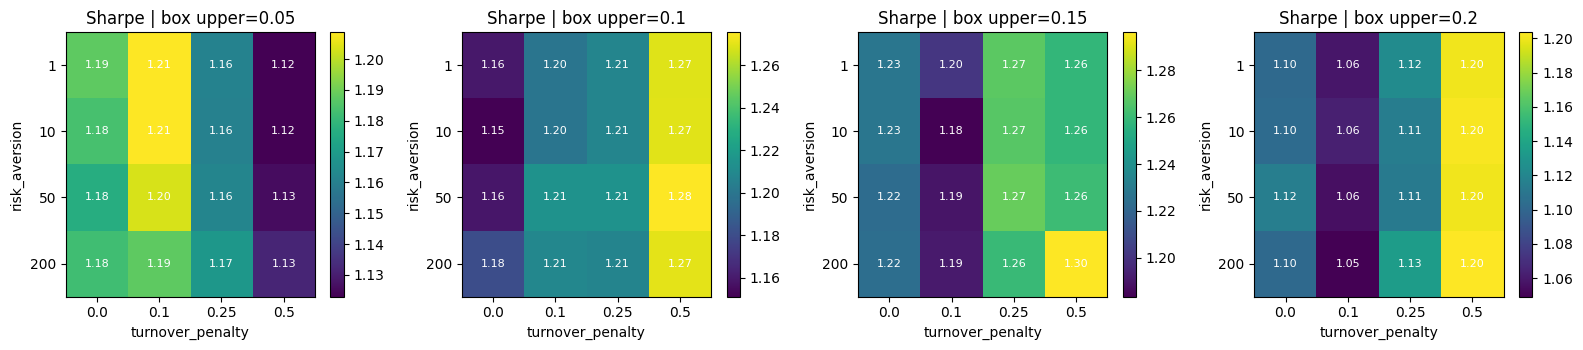

In [16]:
# Load results from disk: ranked table + Sharpe heatmaps
summary = pd.read_csv(os.path.join(SWEEP_DIR, 'summary.csv'))
disp = summary.copy()
for c in ['CAGR', 'Vol', 'MaxDD', 'avg_turnover']:
    disp[c] = (disp[c] * 100).round(2)
disp[['Sharpe', 'IR']] = disp[['Sharpe', 'IR']].round(2)
print('Top 10 configurations by net Sharpe (excess over Swiss rf):')
display(disp.sort_values('Sharpe', ascending=False).head(10))

ubs = sorted(summary['box_upper'].unique())
fig, ax = plt.subplots(1, len(ubs), figsize=(4*len(ubs), 3.6), squeeze=False)
for j, ub in enumerate(ubs):
    piv = summary[summary.box_upper == ub].pivot(index='risk_aversion',
                                                 columns='turnover_penalty', values='Sharpe')
    im = ax[0][j].imshow(piv.values, aspect='auto', cmap='viridis')
    ax[0][j].set_xticks(range(len(piv.columns)))
    ax[0][j].set_xticklabels(piv.columns)
    ax[0][j].set_yticks(range(len(piv.index)))
    ax[0][j].set_yticklabels(piv.index)
    ax[0][j].set_xlabel('turnover_penalty')
    ax[0][j].set_ylabel('risk_aversion')
    ax[0][j].set_title(f'Sharpe | box upper={ub}')
    for (yi, xi), v in np.ndenumerate(piv.values):
        if np.isfinite(v): ax[0][j].text(xi, yi, f'{v:.2f}', ha='center', va='center', color='w', fontsize=8)
    fig.colorbar(im, ax=ax[0][j])
plt.tight_layout()
plt.show()

Report for run: ra200_tp0.5_ub0.15


CAGR%    IR  MaxDD%  Sharpe   Vol%
Full sample  Strategy net  14.92  0.47  -27.57    1.30  11.19
             SPI       5.56   NaN  -53.25    0.41  16.47
GFC 2007-09  Strategy net   2.08  1.51   -4.53    0.24   2.87
             SPI     -37.04   NaN  -51.79   -1.49  29.14
Bull 2009-15 Strategy net  18.13  0.12  -14.63    1.53  11.41
             SPI      15.59   NaN  -28.23    1.05  15.01
COVID 2020   Strategy net -66.71  3.74  -10.61   -5.84  18.33
             SPI     -94.91   NaN  -26.33   -5.96  47.64
2022 selloff Strategy net -20.23 -0.37  -20.98   -2.11  10.29
             SPI     -15.85   NaN  -21.70   -0.95  16.39
Last 5 years Strategy net   3.67 -0.09  -27.57    0.36  13.31
             SPI       4.93   NaN  -26.33    0.42  14.59

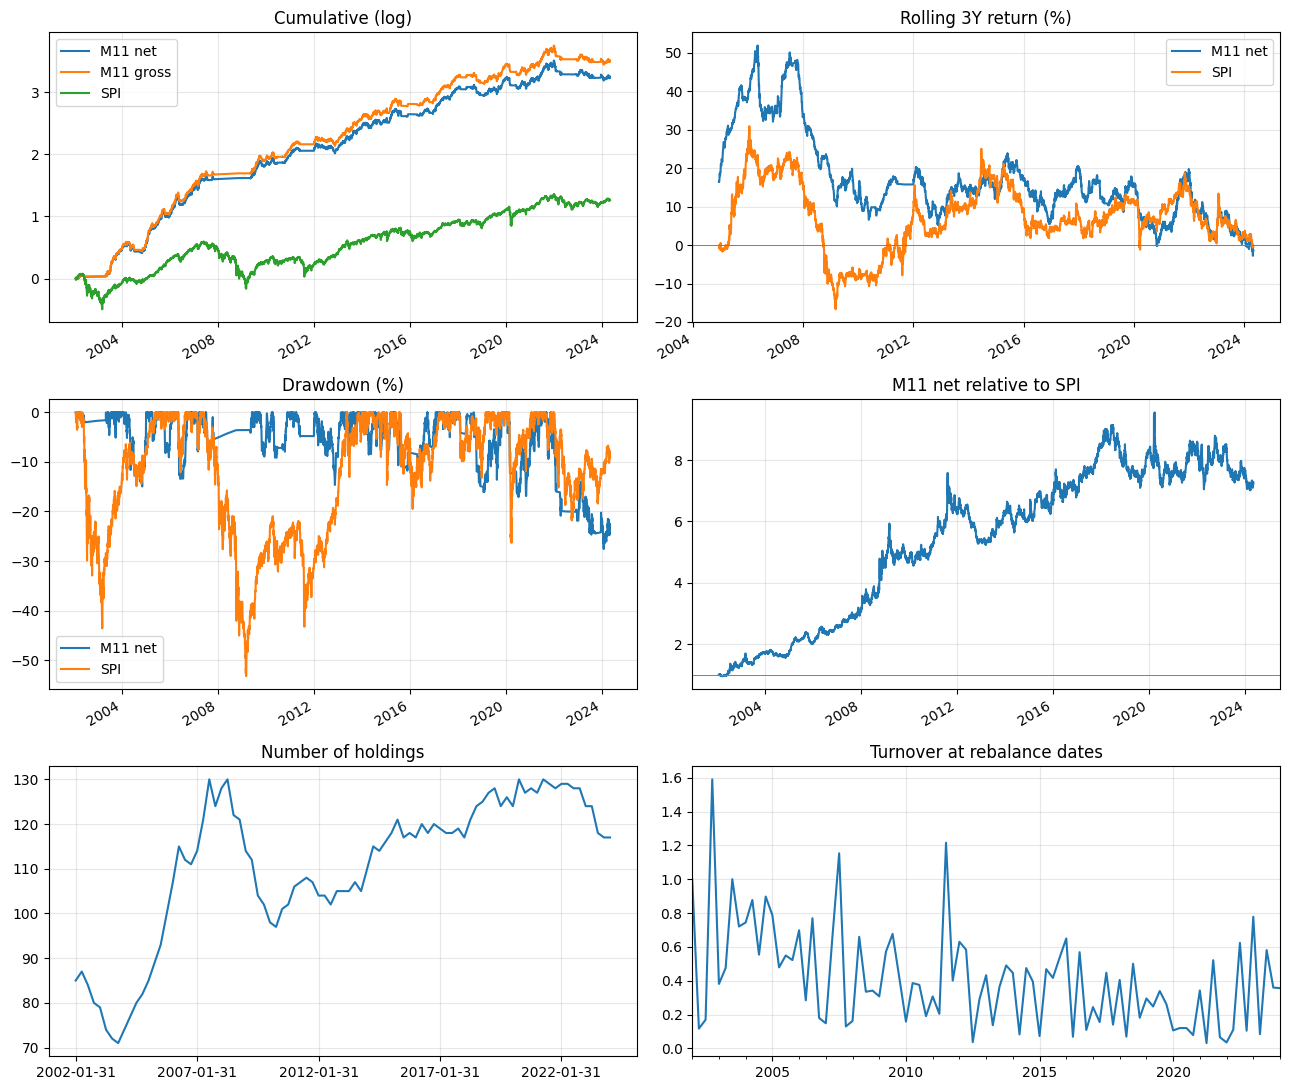

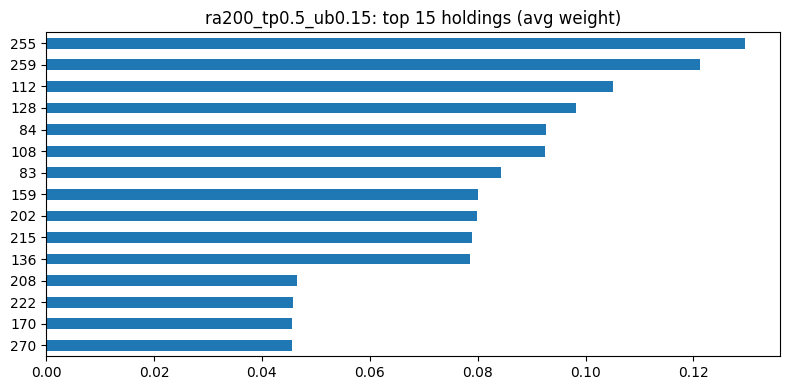

In [ ]:
# Full report for one saved run; default: best by Sharpe
def report_run(run_id=None):
    if run_id is None:
        s = pd.read_csv(os.path.join(SWEEP_DIR, 'summary.csv'))
        run_id = s.sort_values('Sharpe', ascending=False).iloc[0]['run_id']
    d = os.path.join(SWEEP_DIR, run_id)
    ret = pd.read_parquet(os.path.join(d, 'returns.parquet'))
    w   = pd.read_parquet(os.path.join(d, 'weights.parquet'))
    to  = pd.read_parquet(os.path.join(d, 'turnover.parquet'))['turnover']
    to.index = pd.to_datetime(to.index)
    cmp = pd.concat({'Strategy net': ret['net'], 'Strategy gross': ret['gross'], 'SPI': data.bm_series}, axis=1).dropna()
    rf  = srf.build_daily_rf(str(RF_CSV), cmp.index)
    print('Report for run:', run_id)

    def st(r, bm=None, n=252):
        r = r.dropna()
        xs = r - rf.reindex(r.index).fillna(0.0)
        cum = (1 + r).cumprod()
        o = {'CAGR%': ((1+r).prod()**(n/len(r))-1)*100, 'Vol%': r.std()*np.sqrt(n)*100,
             'Sharpe': (xs.mean()*n)/(xs.std()*np.sqrt(n)) if xs.std() > 0 else np.nan,
             'MaxDD%': (cum/cum.cummax()-1).min()*100}
        if bm is not None:
            a = (r - bm.reindex(r.index)).dropna()
            o['IR'] = (a.mean()*n)/(a.std()*np.sqrt(n)) if a.std() > 0 else np.nan
        return pd.Series(o)
    periods = {'Full sample': (cmp.index.min(), cmp.index.max()),
               'GFC 2007-09': ('2007-10-01', '2009-03-09'),
               'Bull 2009-15': ('2009-03-10', '2015-04-30'),
               'COVID 2020':   ('2020-02-19', '2020-03-23'),
               '2022 selloff': ('2022-01-01', '2022-12-31'),
               'Last 5 years': (cmp.index.max() - pd.DateOffset(years=5), cmp.index.max())}
    rows = {}
    for nm, (s0, e0) in periods.items():
        sub = cmp.loc[s0:e0]
        if len(sub) < 20: continue
        rows[(nm, 'Strategy net')] = st(sub['Strategy net'], bm=sub['SPI'])
        rows[(nm, 'SPI')] = st(sub['SPI'])
    display(pd.DataFrame(rows).T.round(2))

    fig, ax = plt.subplots(3, 2, figsize=(13, 11))
    np.log1p(cmp).cumsum().plot(ax=ax[0, 0])
    ax[0, 0].set_title('Cumulative (log)')
    ax[0, 0].grid(alpha=.3)
    ((1+cmp[['Strategy net', 'SPI']]).rolling(756).apply(lambda x: x.prod()**(252/len(x))-1, raw=True)*100
     ).plot(ax=ax[0, 1])
    ax[0, 1].axhline(0, color='grey', lw=.7)
    ax[0, 1].set_title('Rolling 3Y return (%)')
    ax[0, 1].grid(alpha=.3)
    cmp[['Strategy net', 'SPI']].apply(lambda r: ((1+r).cumprod()/(1+r).cumprod().cummax()-1)*100
                                  ).plot(ax=ax[1, 0])
    ax[1, 0].set_title('Drawdown (%)')
    ax[1, 0].grid(alpha=.3)
    ((1+cmp['Strategy net']).cumprod()/(1+cmp['SPI']).cumprod()).plot(ax=ax[1, 1])
    ax[1, 1].axhline(1, color='grey', lw=.7)
    ax[1, 1].set_title('Strategy net relative to SPI')
    ax[1, 1].grid(alpha=.3)
    w.gt(0).sum(axis=1).plot(ax=ax[2, 0], title='Number of holdings')
    ax[2, 0].grid(alpha=.3)
    to.plot(ax=ax[2, 1], title='Turnover at rebalance dates')
    ax[2, 1].grid(alpha=.3)
    plt.tight_layout()
    plt.show()

    w.mean().sort_values(ascending=False).head(15).iloc[::-1].plot(
        kind='barh', figsize=(8, 4), title=f'{run_id}: top 15 holdings (avg weight)')
    plt.tight_layout()
    plt.show()

report_run()

Best configurations by Sharpe ratio


,Risk aversion,Turnover penalty,Max weight,MA window,CAGR (%),Vol (%),Sharpe,Max DD (%),IR vs SPI
0,50,0.25,0.15,120,16.46,10.32,1.53,-27.13,0.54
1,200,0.50,0.15,120,16.46,10.29,1.53,-21.00,0.54
2,10,0.25,0.15,120,16.43,10.33,1.52,-27.14,0.54
3,1,0.25,0.15,120,16.44,10.33,1.52,-27.14,0.54
4,200,0.25,0.15,120,16.17,10.23,1.51,-27.11,0.52
5,200,0.50,0.10,30,12.82,8.25,1.50,-17.75,0.34
6,50,0.50,0.10,120,15.06,9.63,1.50,-25.15,0.48
7,200,0.50,0.15,30,13.96,8.96,1.50,-17.07,0.40
8,200,0.50,0.10,120,14.90,9.52,1.50,-24.96,0.47
9,50,0.50,0.10,30,12.89,8.36,1.49,-17.90,0.35


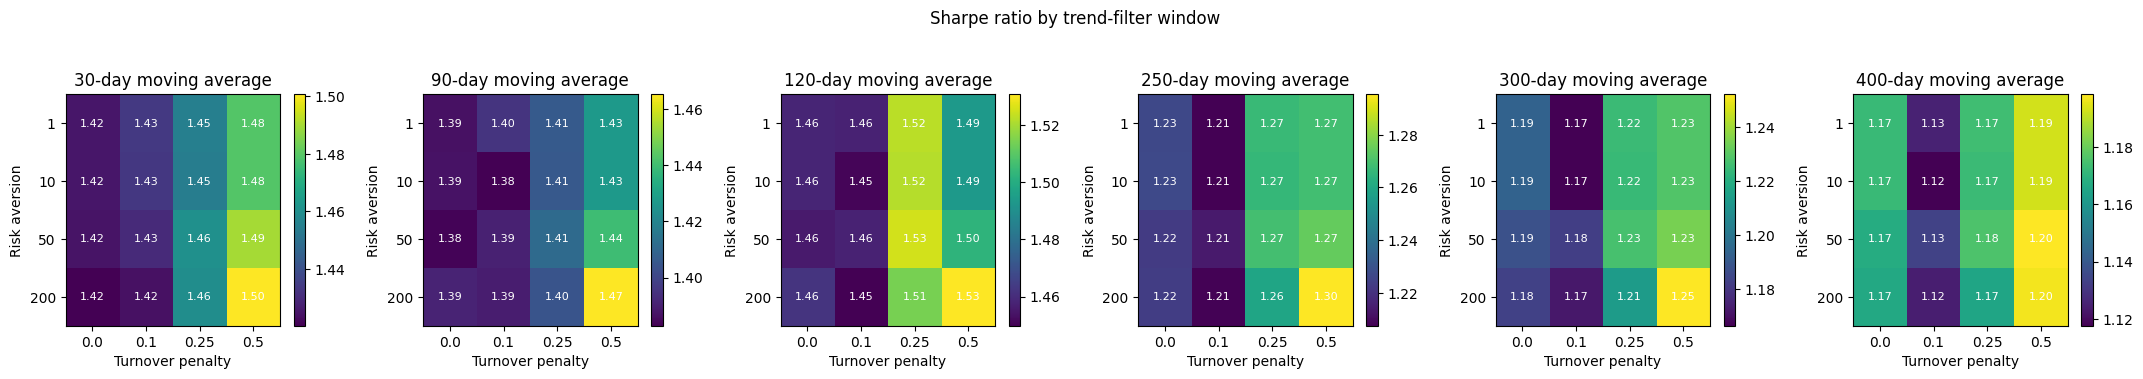

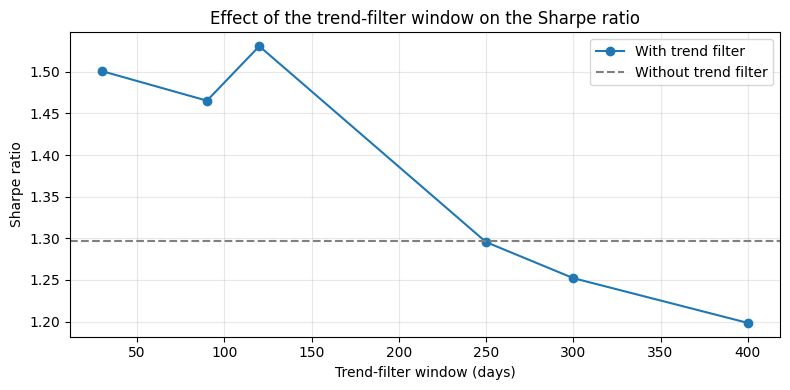

In [ ]:
# Trend-overlay sensitivity: SPI moving-average window vs core parameters
MA_WINDOWS = [30, 90, 120, 250, 300, 400]

SWEEP_DIR_MA = SWEEP_DIR + '_MA'
FIG_DIR_MA = os.path.join(SWEEP_DIR_MA, 'figures')
os.makedirs(SWEEP_DIR_MA, exist_ok=True)
os.makedirs(FIG_DIR_MA, exist_ok=True)

spi_price = (1 + data.bm_series).cumprod()
EXPO = {W: (spi_price > spi_price.rolling(W).mean()).astype(float).shift(1).fillna(0.0)
        for W in MA_WINDOWS}
RF_ALL = srf.build_daily_rf(str(RF_CSV), data.bm_series.index)


def _stats_row(net, n=252):
    cmp = pd.concat({'net': net, 'SPI': data.bm_series}, axis=1).dropna()
    rf = RF_ALL.reindex(cmp.index).fillna(0.0)
    xs = cmp['net'] - rf
    cum = (1 + cmp['net']).cumprod()
    active = (cmp['net'] - cmp['SPI']).dropna()
    return dict(
        CAGR=float((1 + cmp['net']).prod() ** (n / len(cmp)) - 1),
        Vol=float(cmp['net'].std() * np.sqrt(n)),
        Sharpe=float((xs.mean() * n) / (xs.std() * np.sqrt(n))) if xs.std() > 0 else np.nan,
        MaxDD=float((cum / cum.cummax() - 1).min()),
        IR=float((active.mean() * n) / (active.std() * np.sqrt(n))) if active.std() > 0 else np.nan,
    )

base = pd.read_csv(os.path.join(SWEEP_DIR, 'summary.csv'))
sharpe_no_overlay = float(base['Sharpe'].max())

rows = []
for _, r in base.iterrows():
    rid = r['run_id']
    ret = pd.read_parquet(os.path.join(SWEEP_DIR, rid, 'returns.parquet'))
    for W in MA_WINDOWS:
        e = EXPO[W].reindex(ret.index).fillna(0.0)
        rf = RF_ALL.reindex(ret.index).fillna(0.0)
        net = e * ret['net'] + (1 - e) * rf
        gross = e * ret['gross'] + (1 - e) * rf
        out_id = f'{rid}_ma{W}'
        od = os.path.join(SWEEP_DIR_MA, out_id)
        os.makedirs(od, exist_ok=True)
        net.to_frame('net').join(gross.to_frame('gross')).to_parquet(os.path.join(od, 'returns.parquet'))
        row = dict(run_id=out_id, base_run=rid, risk_aversion=r['risk_aversion'],
                   turnover_penalty=r['turnover_penalty'], box_upper=r['box_upper'],
                   ma_window=W, **_stats_row(net))
        json.dump(row, open(os.path.join(od, 'summary.json'), 'w'))
        rows.append(row)

summary_ma = pd.DataFrame(rows)
summary_ma.to_csv(os.path.join(SWEEP_DIR_MA, 'summary.csv'), index=False)

disp = summary_ma.copy()
for c in ['CAGR', 'Vol', 'MaxDD']:
    disp[c] = (disp[c] * 100).round(2)
disp[['Sharpe', 'IR']] = disp[['Sharpe', 'IR']].round(2)
disp = disp.rename(columns={'risk_aversion': 'Risk aversion', 'turnover_penalty': 'Turnover penalty',
                            'box_upper': 'Max weight', 'ma_window': 'MA window',
                            'CAGR': 'CAGR (%)', 'Vol': 'Vol (%)', 'MaxDD': 'Max DD (%)', 'IR': 'IR vs SPI'})
print('Best configurations by Sharpe ratio')
display(disp.sort_values('Sharpe', ascending=False)
        .head(10)[['Risk aversion', 'Turnover penalty', 'Max weight', 'MA window',
                   'CAGR (%)', 'Vol (%)', 'Sharpe', 'Max DD (%)', 'IR vs SPI']]
        .reset_index(drop=True))

fig, ax = plt.subplots(1, len(MA_WINDOWS), figsize=(3.6 * len(MA_WINDOWS), 3.6), squeeze=False)
for j, W in enumerate(MA_WINDOWS):
    sub = summary_ma[summary_ma.ma_window == W]
    piv = sub.pivot_table(index='risk_aversion', columns='turnover_penalty', values='Sharpe', aggfunc='max')
    im = ax[0][j].imshow(piv.values, aspect='auto', cmap='viridis')
    ax[0][j].set_xticks(range(len(piv.columns)))
    ax[0][j].set_xticklabels(piv.columns)
    ax[0][j].set_yticks(range(len(piv.index)))
    ax[0][j].set_yticklabels(piv.index)
    ax[0][j].set_xlabel('Turnover penalty')
    ax[0][j].set_ylabel('Risk aversion')
    ax[0][j].set_title(f'{W}-day moving average')
    for (yi, xi), v in np.ndenumerate(piv.values):
        if np.isfinite(v):
            ax[0][j].text(xi, yi, f'{v:.2f}', ha='center', va='center', color='w', fontsize=8)
    fig.colorbar(im, ax=ax[0][j])
fig.suptitle('Sharpe ratio by trend-filter window', y=1.04)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_MA, 'sharpe_heatmaps_by_window.png'), dpi=130, bbox_inches='tight')
plt.show()

best_per_W = summary_ma.loc[summary_ma.groupby('ma_window')['Sharpe'].idxmax()].sort_values('ma_window')
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(best_per_W['ma_window'], best_per_W['Sharpe'], marker='o', label='With trend filter')
ax.axhline(sharpe_no_overlay, ls='--', color='grey', label='Without trend filter')
ax.set_xlabel('Trend-filter window (days)')
ax.set_ylabel('Sharpe ratio')
ax.set_title('Effect of the trend-filter window on the Sharpe ratio')
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR_MA, 'sharpe_vs_ma_window.png'), dpi=130, bbox_inches='tight')
plt.show()

Configuration: risk aversion 200, turnover penalty 0.5, max weight 0.15, 120-day trend filter

Performance by period (Sharpe and IR computed on excess returns)


CAGR (%)  IR vs SPI  Max DD (%)  \
Period                                                                       
Full sample                Strategy (net)     16.46       0.54      -21.00   
                           SPI                 5.56        NaN      -53.25   
Financial crisis (2007-09) Strategy (net)      1.79       1.50       -4.53   
                           SPI               -37.04        NaN      -51.79   
Post-crisis bull (2009-15) Strategy (net)     18.79       0.15      -12.79   
                           SPI                15.59        NaN      -28.23   
COVID crash (2020)         Strategy (net)    -51.96       4.46       -7.30   
                           SPI               -94.91        NaN      -26.33   
Rate shock (2022)          Strategy (net)    -16.45      -0.10      -17.07   
                           SPI               -15.85        NaN      -21.70   
Last five years            Strategy (net)      5.18      -0.01      -21.00   
                           SPI                 4.93        NaN      -26.33   

                                           Sharpe  Vol (%)  
Period                                                      
Full sample                Strategy (net)    1.53    10.29  
                           SPI               0.41    16.47  
Financial crisis (2007-09) Strategy (net)    0.14     2.87  
                           SPI              -1.49    29.14  
Post-crisis bull (2009-15) Strategy (net)    1.68    10.62  
                           SPI               1.05    15.01  
COVID crash (2020)         Strategy (net)   -4.43    16.01  
                           SPI              -5.96    47.64  
Rate shock (2022)          Strategy (net)   -1.88     9.12  
                           SPI              -0.95    16.39  
Last five years            Strategy (net)    0.50    12.08  
                           SPI               0.42    14.59

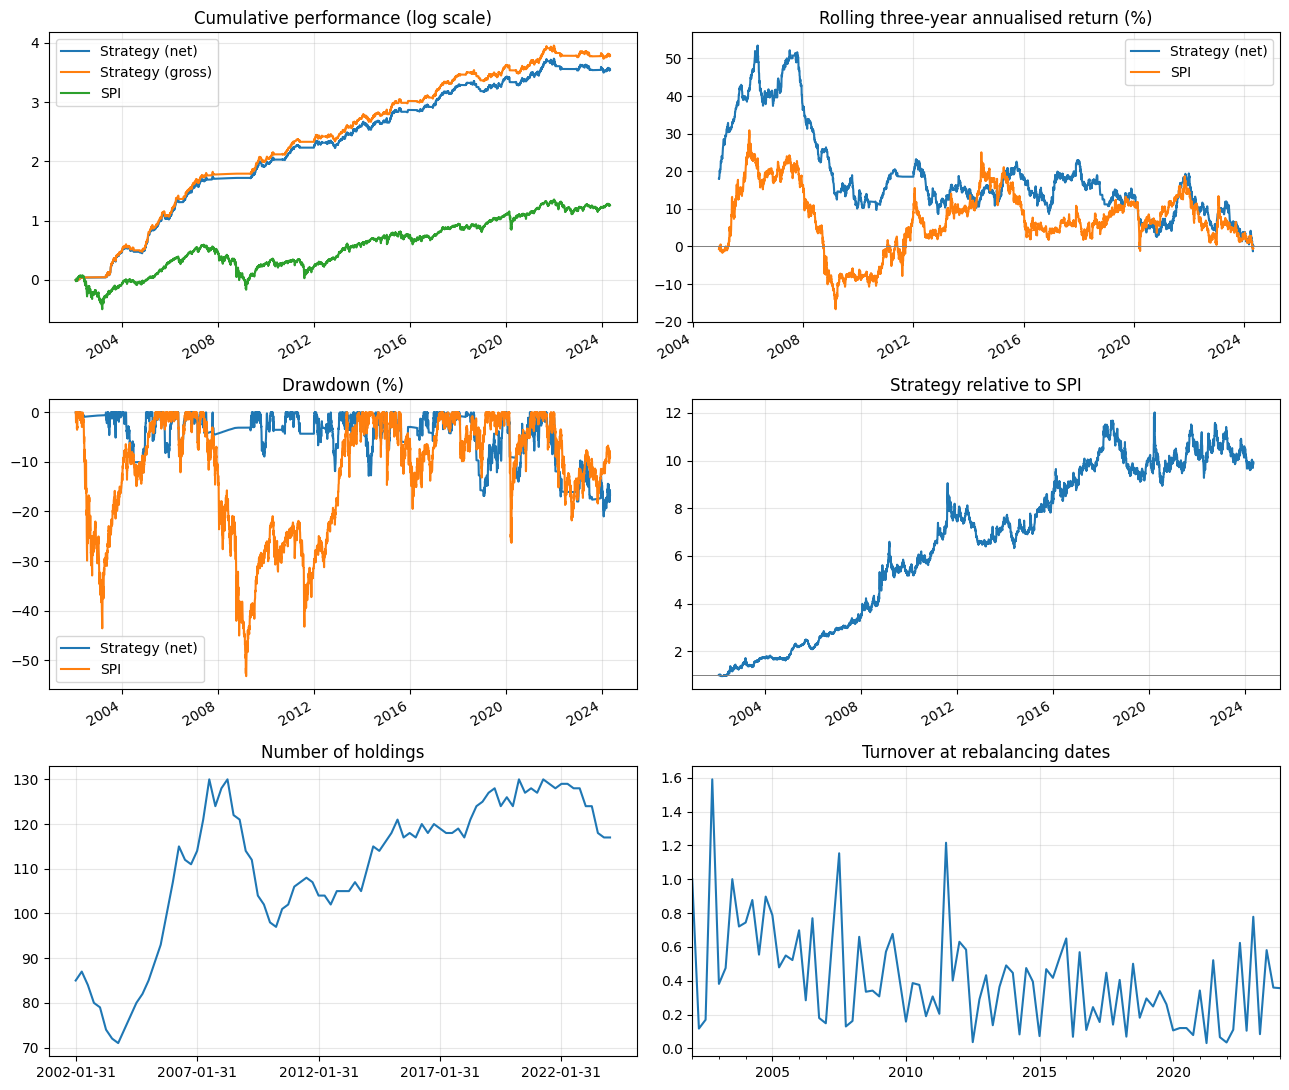

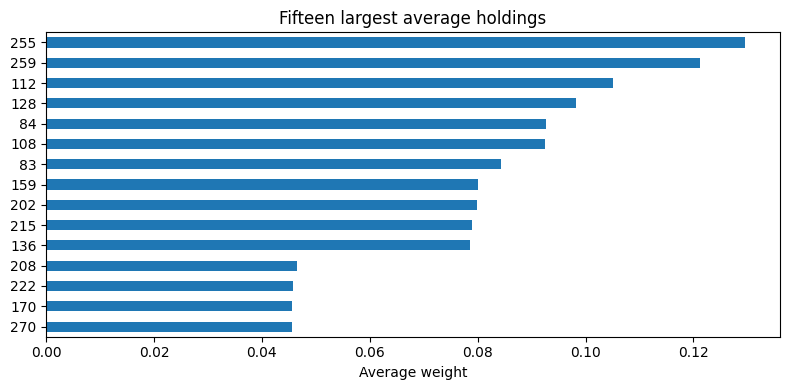

In [19]:
# Detailed performance report for a single configuration
def report_run_ma(run_id=None):
    sm = pd.read_csv(os.path.join(SWEEP_DIR_MA, 'summary.csv'))
    if run_id is None:
        run_id = sm.sort_values('Sharpe', ascending=False).iloc[0]['run_id']
    meta = sm[sm.run_id == run_id].iloc[0]
    base_run = meta['base_run']

    ret = pd.read_parquet(os.path.join(SWEEP_DIR_MA, run_id, 'returns.parquet'))
    w = pd.read_parquet(os.path.join(SWEEP_DIR, base_run, 'weights.parquet'))
    to = pd.read_parquet(os.path.join(SWEEP_DIR, base_run, 'turnover.parquet'))['turnover']
    to.index = pd.to_datetime(to.index)
    cmp = pd.concat({'Strategy (net)': ret['net'], 'Strategy (gross)': ret['gross'],
                     'SPI': data.bm_series}, axis=1).dropna()
    rf = srf.build_daily_rf(str(RF_CSV), cmp.index)
    print(f"Configuration: risk aversion {meta['risk_aversion']}, "
          f"turnover penalty {meta['turnover_penalty']}, max weight {meta['box_upper']}, "
          f"{int(meta['ma_window'])}-day trend filter")

    def st(r, bm=None, n=252):
        r = r.dropna()
        xs = r - rf.reindex(r.index).fillna(0.0)
        cum = (1 + r).cumprod()
        o = {'CAGR (%)': ((1 + r).prod() ** (n / len(r)) - 1) * 100,
             'Vol (%)': r.std() * np.sqrt(n) * 100,
             'Sharpe': (xs.mean() * n) / (xs.std() * np.sqrt(n)) if xs.std() > 0 else np.nan,
             'Max DD (%)': (cum / cum.cummax() - 1).min() * 100}
        if bm is not None:
            a = (r - bm.reindex(r.index)).dropna()
            o['IR vs SPI'] = (a.mean() * n) / (a.std() * np.sqrt(n)) if a.std() > 0 else np.nan
        return pd.Series(o)

    periods = {'Full sample': (cmp.index.min(), cmp.index.max()),
               'Financial crisis (2007-09)': ('2007-10-01', '2009-03-09'),
               'Post-crisis bull (2009-15)': ('2009-03-10', '2015-04-30'),
               'COVID crash (2020)': ('2020-02-19', '2020-03-23'),
               'Rate shock (2022)': ('2022-01-01', '2022-12-31'),
               'Last five years': (cmp.index.max() - pd.DateOffset(years=5), cmp.index.max())}
    rows = {}
    for nm, (s0, e0) in periods.items():
        sub = cmp.loc[s0:e0]
        if len(sub) < 20:
            continue
        rows[(nm, 'Strategy (net)')] = st(sub['Strategy (net)'], bm=sub['SPI'])
        rows[(nm, 'SPI')] = st(sub['SPI'])
    tbl = pd.DataFrame(rows).T.round(2)
    tbl.index.names = ['Period', '']
    tbl.to_csv(os.path.join(SWEEP_DIR_MA, f'report_{run_id}.csv'))
    print('\nPerformance by period (Sharpe and IR computed on excess returns)')
    display(tbl)

    fig, ax = plt.subplots(3, 2, figsize=(13, 11))
    np.log1p(cmp).cumsum().plot(ax=ax[0, 0])
    ax[0, 0].set_title('Cumulative performance (log scale)')
    ax[0, 0].grid(alpha=.3)
    ((1 + cmp[['Strategy (net)', 'SPI']]).rolling(756).apply(lambda x: x.prod() ** (252 / len(x)) - 1, raw=True) * 100
     ).plot(ax=ax[0, 1])
    ax[0, 1].axhline(0, color='grey', lw=.7)
    ax[0, 1].set_title('Rolling three-year annualised return (%)')
    ax[0, 1].grid(alpha=.3)
    cmp[['Strategy (net)', 'SPI']].apply(lambda r: ((1 + r).cumprod() / (1 + r).cumprod().cummax() - 1) * 100
                                         ).plot(ax=ax[1, 0])
    ax[1, 0].set_title('Drawdown (%)')
    ax[1, 0].grid(alpha=.3)
    ((1 + cmp['Strategy (net)']).cumprod() / (1 + cmp['SPI']).cumprod()).plot(ax=ax[1, 1])
    ax[1, 1].axhline(1, color='grey', lw=.7)
    ax[1, 1].set_title('Strategy relative to SPI')
    ax[1, 1].grid(alpha=.3)
    w.gt(0).sum(axis=1).plot(ax=ax[2, 0], title='Number of holdings')
    ax[2, 0].grid(alpha=.3)
    to.plot(ax=ax[2, 1], title='Turnover at rebalancing dates')
    ax[2, 1].grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(os.path.join(SWEEP_DIR_MA, 'figures', f'report_{run_id}.png'), dpi=130, bbox_inches='tight')
    plt.show()

    w.mean().sort_values(ascending=False).head(15).iloc[::-1].plot(
        kind='barh', figsize=(8, 4), title='Fifteen largest average holdings')
    plt.xlabel('Average weight')
    plt.tight_layout()
    plt.savefig(os.path.join(SWEEP_DIR_MA, 'figures', f'topweights_{run_id}.png'), dpi=130, bbox_inches='tight')
    plt.show()


report_run_ma()